# Notebook 64 — PointNet and learning from point clouds

A point cloud is an unordered set of sampled 3D coordinates. A neural network must therefore produce the same object-level result when the rows are permuted.

This notebook builds a small PointNet-style classifier for synthetic spheres, cubes, and cylinders. The purpose is to understand shared point processing, symmetric aggregation, sampling behavior, and point-set distances—not to reach benchmark accuracy.

Related material:

- [Notebook 63 — 3D representations and geometric intuition](63_3d_representations_and_geometric_intuition.ipynb)
- [Learning from 3D data](../notes/15-3d-vision/learning-from-3d-data.md)

## Learning goals

- interpret point-cloud batches shaped (N, P, 3);
- apply one shared network independently to every point;
- aggregate unordered point features symmetrically;
- train a small PointNet classifier;
- distinguish permutation invariance from sampling invariance;
- inspect points selected by max pooling;
- implement and interpret Chamfer distance.

In [22]:
from __future__ import annotations

import random
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from cs231n_practice.geometry import (
    rotation_x,
    rotation_y,
    rotation_z,
    sample_sphere_surface,
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
rng = np.random.default_rng(SEED)

if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
elif torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
else:
    DEVICE = torch.device("cpu")

CLASS_NAMES = ("sphere", "cube", "cylinder")
print("device:", DEVICE)

device: mps


## 1. Synthetic point-cloud dataset

Every example contains $P$ rows and three coordinate columns:

$$
X\in\mathbb{R}^{P\times3}.
$$

The batch shape (N, P, 3) means:

- $N$: objects in the batch;
- $P$: sampled points per object;
- $3$: the $x$, $y$, and $z$ coordinates.

We sample object surfaces, apply a random 3D rotation and small noise, then normalize each cloud. Centering and scaling remove absolute position and size so the classifier must focus on shape.

In [23]:
def sample_cube_surface(number_points, *, generator):
    """Sample points from the six faces of a cube spanning [-1, 1]^3."""
    face_ids = generator.integers(0, 6, size=number_points)
    points = generator.uniform(-1.0, 1.0, size=(number_points, 3))
    axes = face_ids // 2
    signs = np.where(face_ids % 2 == 0, -1.0, 1.0)
    points[np.arange(number_points), axes] = signs
    return points


def sample_cylinder_surface(number_points, *, generator):
    """Sample the side and caps of a unit-radius, height-two cylinder."""
    points = np.empty((number_points, 3), dtype=np.float64)
    regions = generator.choice(3, size=number_points, p=(2 / 3, 1 / 6, 1 / 6))
    angles = generator.uniform(0.0, 2.0 * np.pi, size=number_points)

    side = regions == 0
    points[side, 0] = np.cos(angles[side])
    points[side, 1] = np.sin(angles[side])
    points[side, 2] = generator.uniform(-1.0, 1.0, size=side.sum())

    for region, height in ((1, -1.0), (2, 1.0)):
        cap = regions == region
        radii = np.sqrt(generator.uniform(0.0, 1.0, size=cap.sum()))
        points[cap, 0] = radii * np.cos(angles[cap])
        points[cap, 1] = radii * np.sin(angles[cap])
        points[cap, 2] = height
    return points


def normalize_point_cloud(points):
    centered = points - points.mean(axis=0, keepdims=True)
    return centered / np.linalg.norm(centered, axis=1).max()


def random_rotation(generator):
    angles = generator.uniform(0.0, 2.0 * np.pi, size=3)
    return rotation_z(angles[2]) @ rotation_y(angles[1]) @ rotation_x(angles[0])


def sample_shape(label, number_points, *, generator, noise_std=0.015):
    if label == 0:
        points = sample_sphere_surface(number_points, generator=generator)
    elif label == 1:
        points = sample_cube_surface(number_points, generator=generator)
    elif label == 2:
        points = sample_cylinder_surface(number_points, generator=generator)
    else:
        raise ValueError("unknown shape label")

    points = points @ random_rotation(generator).T
    points += generator.normal(scale=noise_std, size=points.shape)
    return normalize_point_cloud(points)


def make_point_cloud_dataset(number_examples, number_points, *, seed):
    generator = np.random.default_rng(seed)
    labels = np.arange(number_examples) % len(CLASS_NAMES)
    generator.shuffle(labels)
    clouds = np.stack([
        sample_shape(int(label), number_points, generator=generator)
        for label in labels
    ])
    return (
        torch.tensor(clouds, dtype=torch.float32),
        torch.tensor(labels, dtype=torch.long),
    )

### Exercise 1 — Inspect shapes and tensor dimensions

Create datasets with 64 points per object. Complete the expected shapes and find one example from each class for visualization.

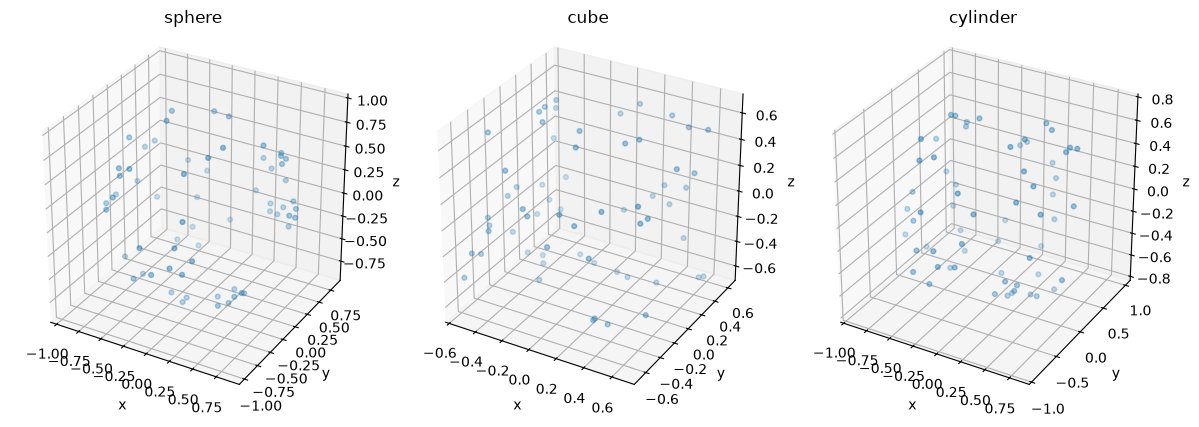

In [24]:
NUMBER_POINTS = 64

train_clouds, train_labels = make_point_cloud_dataset(900, NUMBER_POINTS, seed=SEED)
validation_clouds, validation_labels = make_point_cloud_dataset(
    300, NUMBER_POINTS, seed=SEED + 1
)

# complete the expected shapes.
assert train_clouds.shape == (900, NUMBER_POINTS, 3)
assert train_labels.shape == (900,)
assert validation_clouds.shape == (300, NUMBER_POINTS, 3)
assert validation_labels.shape == (300,)
assert train_clouds.dtype == torch.float32
assert train_labels.dtype == torch.long
assert validation_clouds.dtype == torch.float32
assert validation_labels.dtype == torch.long

fig = plt.figure(figsize=(12, 4))
for label, class_name in enumerate(CLASS_NAMES):
    # find the first training index whose label equals label.
    example_index = next(i for i, l in enumerate(train_labels) if l == label)
    points = train_clouds[example_index].numpy()
    axis = fig.add_subplot(1, 3, label + 1, projection="3d")
    axis.scatter(points[:, 0], points[:, 1], points[:, 2], s=12, alpha=0.7)
    axis.set(title=class_name, xlabel="x", ylabel="y", zlabel="z")
    axis.set_box_aspect((1, 1, 1))
plt.tight_layout()
plt.show()

## 2. One shared network processes every point

PointNet does not flatten all points into one ordered vector. The same transformation $h$ is applied independently to every row:

$$
x_i\in\mathbb{R}^3
\longrightarrow
h(x_i)\in\mathbb{R}^D.
$$

A PyTorch linear layer transforms only the final axis. Input shaped (N, P, 3) therefore becomes (N, P, D). “Shared” means every point uses the same weights; it does not mean every point obtains equal features.

### Exercise 2 — Apply shared transformations

Apply the point network directly to the complete batch without flattening it.

In [25]:
POINT_FEATURE_DIM = 64

point_network = nn.Sequential(
    nn.Linear(3, 32),
    nn.ReLU(),
    nn.Linear(32, POINT_FEATURE_DIM),
    nn.ReLU(),
)
example_batch = train_clouds[:5]

# apply point_network to the full (N, P, 3) tensor.
point_features = point_network(example_batch)

assert point_features.shape == (5, NUMBER_POINTS, POINT_FEATURE_DIM)
single_point_features = point_network(example_batch[:, 7])
torch.testing.assert_close(point_features[:, 7], single_point_features)
print("input:", tuple(example_batch.shape))
print("point features:", tuple(point_features.shape))

input: (5, 64, 3)
point features: (5, 64, 64)


## 3. Symmetric aggregation removes order

PointNet needs one representation per object. Coordinate-wise maximum is symmetric: reordering input points does not change it.

$$
g(\{x_i\})=\max_i h(x_i).
$$

The shape transformation is

$$
(N,P,D)\longrightarrow(N,D),
$$

where pooling occurs over the point axis $P$.

### Exercise 3 — Implement a tiny PointNet

Complete the forward pass. Note that 'torch.max' returns both maximum values and the indices of the winning points.

In [26]:
class TinyPointNet(nn.Module):
    """Classify point clouds using shared features and max pooling."""

    def __init__(self, number_classes=3, point_feature_dim=64):
        super().__init__()
        self.point_network = nn.Sequential(
            nn.Linear(3, 32),
            nn.ReLU(),
            nn.Linear(32, point_feature_dim),
            nn.ReLU(),
        )
        self.classifier = nn.Sequential(
            nn.Linear(point_feature_dim, 32),
            nn.ReLU(),
            nn.Linear(32, number_classes),
        )

    def forward(self, point_clouds, *, return_pool_indices=False):
        # calculate point features with shape (N, P, D).
        point_features = self.point_network(point_clouds)
        # take coordinate-wise maxima over dim=1.
        global_features, pool_indices = point_features.max(dim=1)
        # calculate class logits from the global features.
        logits = self.classifier(global_features)
        if return_pool_indices:
            return logits, pool_indices
        return logits


shape_model = TinyPointNet()
shape_logits, shape_pool_indices = shape_model(
    train_clouds[:6], return_pool_indices=True
)
assert shape_logits.shape == (6, len(CLASS_NAMES))
assert shape_pool_indices.shape == (6, POINT_FEATURE_DIM)

## 4. Permutation invariance is architectural

If point rows are shuffled, the shared network produces the same feature set in another order. Symmetric max pooling then produces the same global representation.

This guarantee comes from the architecture, not merely from training with shuffled data.

### Exercise 4 — Verify permutation invariance

Reorder only the point axis and compare the resulting logits.

In [27]:
torch.manual_seed(SEED)
permutation = torch.randperm(NUMBER_POINTS)
original_batch = validation_clouds[:16]

# apply permutation to the point axis.
permuted_batch = original_batch[:, permutation]

shape_model.eval()
with torch.no_grad():
    original_logits = shape_model(original_batch)
    permuted_logits = shape_model(permuted_batch)

torch.testing.assert_close(original_logits, permuted_logits, atol=1e-6, rtol=1e-6)
print("maximum difference:", (original_logits - permuted_logits).abs().max().item())

maximum difference: 0.0


## 5. Train the classifier

The point-cloud-specific idea lies in the architecture; training still uses ordinary multiclass cross-entropy.

### Exercise 5 — Complete the training update

Calculate logits and loss, reset gradients, backpropagate, and update the parameters.

final loss=0.5232, validation accuracy=0.737


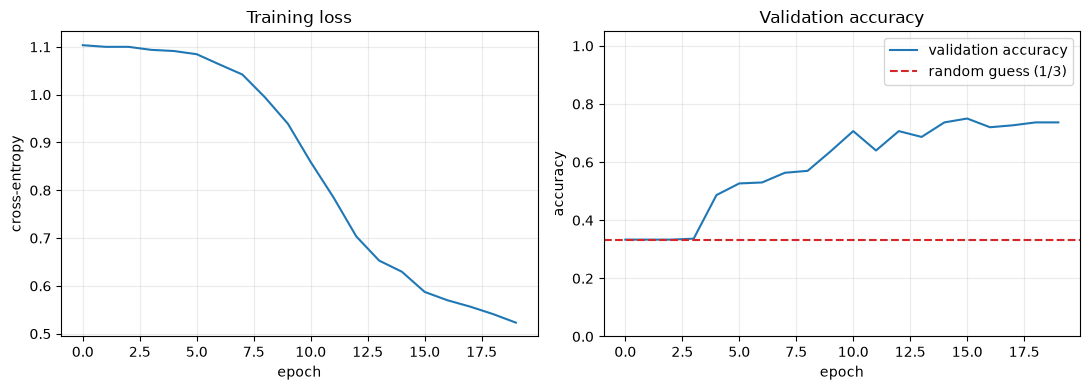

In [28]:
def classification_accuracy(model, point_clouds, labels, *, device):
    model.eval()
    with torch.no_grad():
        predictions = model(point_clouds.to(device)).argmax(dim=1).cpu()
    return (predictions == labels).float().mean().item()


torch.manual_seed(SEED)
model = TinyPointNet().to(DEVICE)
optimizer = torch.optim.Adam(model.parameters(), lr=2e-3)
loss_function = nn.CrossEntropyLoss()
training_loader = DataLoader(
    TensorDataset(train_clouds, train_labels),
    batch_size=64,
    shuffle=True,
    generator=torch.Generator().manual_seed(SEED),
)

training_losses = []
validation_accuracies = []
random_guess_accuracy = 1.0 / len(CLASS_NAMES)

for epoch in range(20):
    model.train()
    epoch_losses = []
    for point_batch, label_batch in training_loader:
        point_batch = point_batch.to(DEVICE)
        label_batch = label_batch.to(DEVICE)

        # calculate logits and cross-entropy loss.
        logits = model(point_batch)
        loss = loss_function(logits, label_batch)
        # reset gradients, backpropagate, and update parameters.
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        epoch_losses.append(loss.item())

    training_losses.append(float(np.mean(epoch_losses)))
    validation_accuracies.append(
        classification_accuracy(
            model, validation_clouds, validation_labels, device=DEVICE
        )
    )

print(
    f"final loss={training_losses[-1]:.4f}, "
    f"validation accuracy={validation_accuracies[-1]:.3f}"
)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(training_losses)
axes[0].set(title="Training loss", xlabel="epoch", ylabel="cross-entropy")
axes[1].plot(validation_accuracies, label="validation accuracy")
axes[1].axhline(
    random_guess_accuracy,
    color="tab:red",
    linestyle="--",
    label="random guess (1/3)",
)
axes[1].set(title="Validation accuracy", xlabel="epoch", ylabel="accuracy", ylim=(0, 1.05))
axes[1].legend()
for axis in axes:
    axis.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## 6. Permutation invariance is not sampling invariance

Permutation invariance means the same points in another order give the same result.

Sampling invariance would mean different point samples from the same surface give the same result. PointNet does not guarantee this: a sparse sample may miss important regions or produce different maximum features.

### Exercise 6 — Test sampling density

Create fresh validation sets containing different numbers of sampled points. The model accepts all of them because its learned layers do not require a fixed $P$.

  8 points: accuracy=0.343
 16 points: accuracy=0.403
 32 points: accuracy=0.597
 64 points: accuracy=0.763
128 points: accuracy=0.777
256 points: accuracy=0.730
512 points: accuracy=0.690


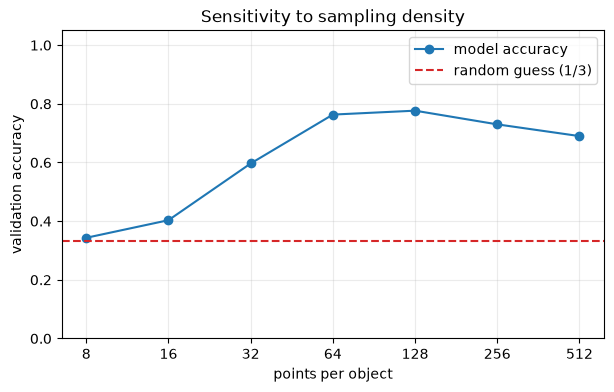

In [29]:
sampling_sizes = (8, 16, 32, 64, 128, 256, 512)
sampling_accuracies = []

for number_points in sampling_sizes:
    # create a fresh 300-example dataset with number_points per object.
    sampled_clouds, sampled_labels = make_point_cloud_dataset(
        300, number_points, seed=SEED + 2
    )
    accuracy = classification_accuracy(
        model, sampled_clouds, sampled_labels, device=DEVICE
    )
    sampling_accuracies.append(accuracy)
    print(f"{number_points:>3} points: accuracy={accuracy:.3f}")

plt.figure(figsize=(7, 4))
plt.plot(sampling_sizes, sampling_accuracies, marker="o", label="model accuracy")
plt.axhline(
    random_guess_accuracy,
    color="tab:red",
    linestyle="--",
    label="random guess (1/3)",
)
plt.xscale("log", base=2)
plt.xticks(sampling_sizes, sampling_sizes)
plt.ylim(0, 1.05)
plt.xlabel("points per object")
plt.ylabel("validation accuracy")
plt.title("Sensitivity to sampling density")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

## 7. Critical points from max pooling

Max pooling returns one winning point index for every feature channel. The union of these winners is sometimes called a set of **critical points**: they directly determine the global maximum feature for this example.

One point may win several channels, and many points may win none.

### Exercise 7 — Visualize selected points

Count how many feature channels selected each input point and highlight points selected at least once.

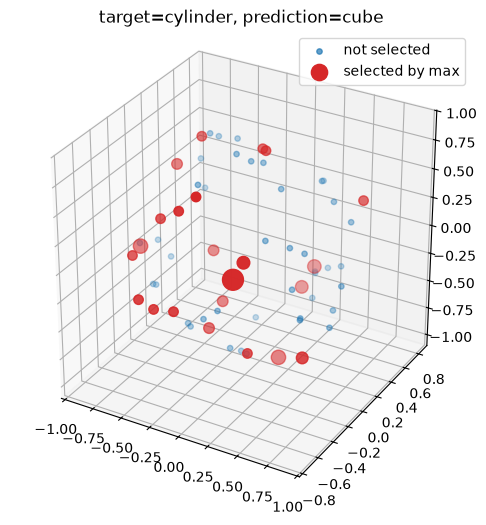

23 of 64 points supplied 64 channel maxima


In [30]:
example_cloud = validation_clouds[:1].to(DEVICE)
model.eval()
with torch.no_grad():
    example_logits, pool_indices = model(
        example_cloud, return_pool_indices=True
    )

# move the first example's point indices to CPU.
winning_indices = pool_indices[0].cpu().numpy()
# count wins for all NUMBER_POINTS positions.
win_counts = np.bincount(winning_indices, minlength=NUMBER_POINTS)
critical_mask = win_counts > 0

points = example_cloud[0].cpu().numpy()
prediction = int(example_logits.argmax(dim=1).item())

fig = plt.figure(figsize=(7, 6))
axis = fig.add_subplot(projection="3d")
axis.scatter(
    points[~critical_mask, 0],
    points[~critical_mask, 1],
    points[~critical_mask, 2],
    s=15,
    alpha=0.7,
    label="not selected",
)
axis.scatter(
    points[critical_mask, 0],
    points[critical_mask, 1],
    points[critical_mask, 2],
    s=35 + 12 * win_counts[critical_mask],
    color="tab:red",
    label="selected by max",
)
axis.set_title(
    f"target={CLASS_NAMES[int(validation_labels[0])]}, "
    f"prediction={CLASS_NAMES[prediction]}"
)
axis.set_box_aspect((1, 1, 1))
axis.legend()
plt.show()

print(
    f"{critical_mask.sum()} of {NUMBER_POINTS} points supplied "
    f"{POINT_FEATURE_DIM} channel maxima"
)

## 8. Max versus mean aggregation

Both maximum and mean are symmetric and therefore permutation invariant.

- Max pooling detects whether a strongly activating point exists.
- Mean pooling summarizes what is typical across all sampled points.

Max may focus on distinctive geometry but depend on whether a critical region was sampled. Mean uses every point but can dilute rare features. Training a second mean-pooling model is left as an optional extension.

## 9. Chamfer distance for unordered point sets

A row-wise distance assumes corresponding row indices, which independently sampled point sets do not have.

A common squared Chamfer distance is

$$
d_{CD}(A,B)=
\frac{1}{|A|}\sum_{a\in A}\min_{b\in B}\lVert a-b\rVert_2^2
+
\frac{1}{|B|}\sum_{b\in B}\min_{a\in A}\lVert b-a\rVert_2^2.
$$

Both directions are needed. Using only $A\rightarrow B$ could ignore unrelated extra points in $B$.

### Exercise 8 — Implement Chamfer distance

Use broadcasting to construct pairwise differences shaped (P, Q, 3), then find nearest neighbors in both directions.

In [31]:
def chamfer_distance(first_points, second_points):
    """Return symmetric mean squared nearest-neighbor distance."""
    if first_points.ndim != 2 or first_points.shape[1] != 3:
        raise ValueError("first_points must have shape (P, 3)")
    if second_points.ndim != 2 or second_points.shape[1] != 3:
        raise ValueError("second_points must have shape (Q, 3)")

    # construct differences with shape (P, Q, 3).
    differences = first_points[:, np.newaxis, :] - second_points[np.newaxis, :, :]
    # sum squared coordinate differences to shape (P, Q).
    squared_distances = np.sum(differences**2, axis=2)
    # average nearest distances in both directions and add them.
    return np.mean(np.min(squared_distances, axis=1)) + np.mean(np.min(squared_distances, axis=0))


small_first = np.array([[0.0, 0.0, 0.0], [2.0, 0.0, 0.0]])
small_second = np.array([[0.0, 0.0, 0.0], [3.0, 0.0, 0.0]])
np.testing.assert_allclose(chamfer_distance(small_first, small_first), 0.0)
np.testing.assert_allclose(chamfer_distance(small_first, small_second), 1.0)

reference = validation_clouds[0].numpy()
permuted = reference[rng.permutation(len(reference))]
noisy = reference + rng.normal(scale=0.08, size=reference.shape)
translated = reference + np.array([0.4, 0.0, 0.0])

print("same points, permuted:", chamfer_distance(reference, permuted))
print("noisy points:         ", chamfer_distance(reference, noisy))
print("translated points:    ", chamfer_distance(reference, translated))

same points, permuted: 0.0
noisy points:          0.027782009166774282
translated points:     0.1624071832584274


### Chamfer distance versus Earth Mover's Distance

Chamfer distance assigns each point its nearest neighbor independently, so several points may choose the same match.

Earth Mover's Distance searches for a one-to-one transport between equally sized sets. It captures global correspondence more directly but is substantially more expensive. We keep it conceptual here.

## Reflection

1. Why can one linear layer process (N, P, 3) without flattening it?

   **Answer:** `nn.Linear` transforms only the final axis. It therefore applies the same $3\rightarrow D$ transformation independently to every one of the $P$ points in each of the $N$ objects.

2. Which axis does PointNet pool over, and why?

   **Answer:** It pools over the point axis $P$ (`dim=1`), combining all point features into one fixed-size representation per object.

3. Why is max pooling permutation invariant?

   **Answer:** Reordering the points does not change the maximum value in any feature channel.

4. What is the difference between permutation invariance and sampling invariance?

   **Answer:** Permutation invariance concerns the same points in a different order. Sampling invariance would require the same output for different sets of points sampled from the same surface, which PointNet does not guarantee.

5. Why can the trained model accept a different number of points?

   **Answer:** The shared point network accepts any number of rows, and max pooling reduces any number of point features to one fixed-size vector.

6. What do the critical points represent?

   **Answer:** They are the points that supply the maximum value for at least one feature channel and therefore directly influence the pooled representation.

7. Why does Chamfer distance use nearest neighbors in both directions?

   **Answer:** One direction checks whether every point in $A$ is near some point in $B$; the reverse direction also checks whether every point in $B$ is represented by $A$. This prevents unmatched extra regions in either set from being ignored.

8. What important 3D information is absent from these point clouds?

   **Answer:** The clouds lack explicit surface connectivity, such as mesh edges and faces. They also contain no surface normals, texture, or color in this example.